<h1 align=center style="line-height:300%;font-family:vazir;color:#0099cc">
<font face="vazir" color="#0099cc">
پروژه دوم درس داده کاوی
</font>
</h1>
<h3 align=center style="line-height:100%;font-family:vazir;color:#0099cc">
استاد درس: دکتر ناظرفرد
</h3>
<h5 align=center style="font-size: 20px;line-height:100%;font-family:vazir;color:#0099cc">
طراح تمرین عملی: فرهاد امان  
    </h5>

## Importing Libraries

In [21]:
# آرین عبداللهی 40023055
import pandas as pd
import numpy as np
from math import sqrt
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error

## Loading Data to Pandas DataFrame

In [22]:
df = pd.read_csv("C:\\Users\\Arian\\Desktop\\Dm_project2\\real-estate.csv", index_col = 0) #load data
df

,X1 transaction date,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,X5 latitude,X6 longitude,Y house price of unit area
No,,,,,,,
1,2012.917,32.0,84.87882,10,24.98298,121.54024,37.9
2,2012.917,19.5,306.59470,9,24.98034,121.53951,42.2
3,2013.583,13.3,561.98450,5,24.98746,121.54391,47.3
4,2013.500,13.3,561.98450,5,24.98746,121.54391,54.8
5,2012.833,5.0,390.56840,5,24.97937,121.54245,43.1
...,...,...,...,...,...,...,...
410,2013.000,13.7,4082.01500,0,24.94155,121.50381,15.4
411,2012.667,5.6,90.45606,9,24.97433,121.54310,50.0
412,2013.250,18.8,390.96960,7,24.97923,121.53986,40.6


## Droping Unnecessary Columns

In [23]:
df=df.drop(df.columns[[0,4,5]], axis=1) #drop unimportant columns
df.head(7)

,X2 house age,X3 distance to the nearest MRT station,X4 number of convenience stores,Y house price of unit area
No,,,,
1,32.0,84.87882,10,37.9
2,19.5,306.59470,9,42.2
3,13.3,561.98450,5,47.3
4,13.3,561.98450,5,54.8
5,5.0,390.56840,5,43.1
6,7.1,2175.03000,3,32.1
7,34.5,623.47310,7,40.3


## Splitting Data to Train and Test

In [24]:
X = df.loc[:,(df.columns != "Y house price of unit area")]  
Y = df["Y house price of unit area"]

X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size = 0.30, random_state = 1)
X_train.shape

(289, 3)

## Visualizing Data Distribution and Correlation

Text(0, 0.5, 'Price of unit area')

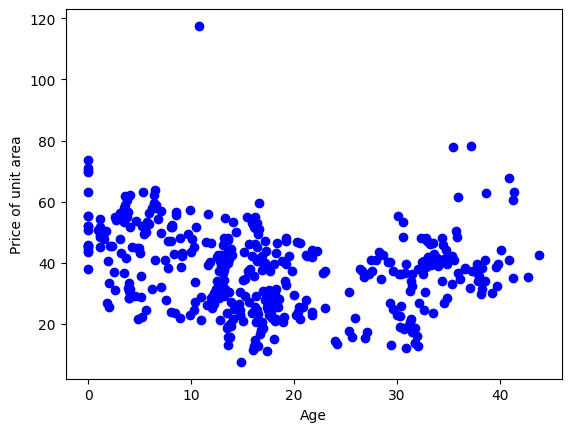

In [25]:
plt.show()
x = X["X2 house age"]
y = Y
plt.scatter(x,y,c='b')
plt.xlabel('Age')
plt.ylabel('Price of unit area')

Text(0, 0.5, 'Price of unit area"')

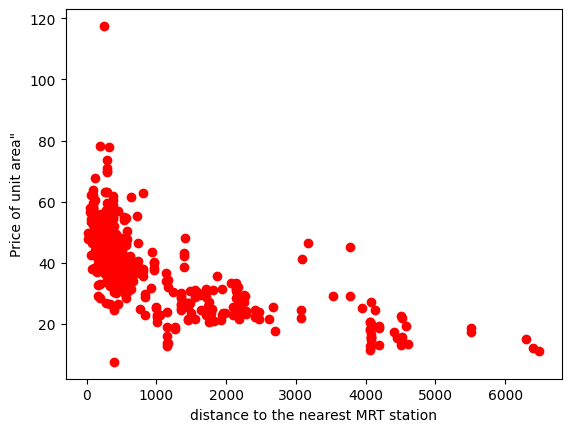

In [26]:
plt.show()
x = X["X3 distance to the nearest MRT station"]
y = Y
plt.scatter(x,y,c='r')
plt.xlabel("distance to the nearest MRT station")
plt.ylabel('Price of unit area"')

Text(0, 0.5, 'Price of unit area')

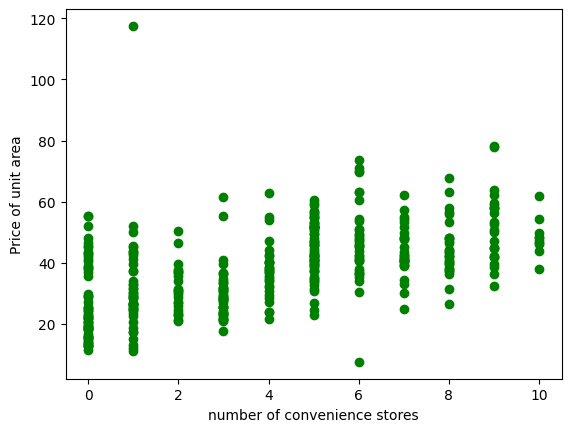

In [27]:
plt.show()
x = X["X4 number of convenience stores"]
y = Y
plt.scatter(x,y,c='g')
plt.xlabel("number of convenience stores")
plt.ylabel('Price of unit area')


                                        X2 house age  \
X2 house age                                    1.00   
X3 distance to the nearest MRT station          0.03   
X4 number of convenience stores                 0.05   
Y house price of unit area                     -0.21   

                                        X3 distance to the nearest MRT station  \
X2 house age                                                              0.03   
X3 distance to the nearest MRT station                                    1.00   
X4 number of convenience stores                                          -0.60   
Y house price of unit area                                               -0.67   

                                        X4 number of convenience stores  \
X2 house age                                                       0.05   
X3 distance to the nearest MRT station                            -0.60   
X4 number of convenience stores                                    1.00   
Y house 

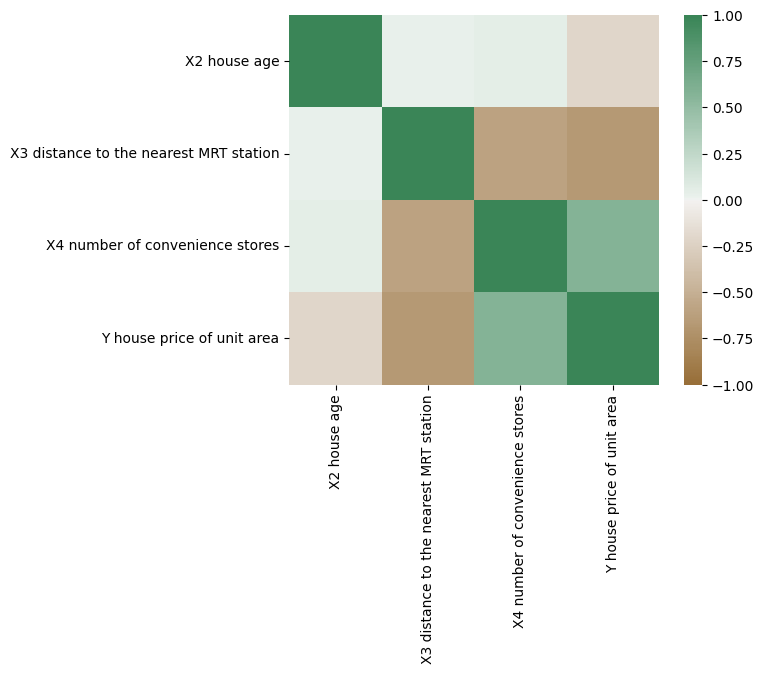

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns
Corr_Matrix = round(df.corr(),2)
print(Corr_Matrix)

correlation_df = df.corr()

axis_corr = sns.heatmap(
correlation_df,
vmin=-1, vmax=1, center=0,
cmap=sns.diverging_palette(50, 500, n=500),
square=True
)

plt.show()

## Linear Regression

mae :  6.516305045616777
mse :  10.715734910088262
                                  Columns  Coefficient Estimate
0                            X2 house age             -0.210181
1  X3 distance to the nearest MRT station             -0.004942
2         X4 number of convenience stores              1.402933


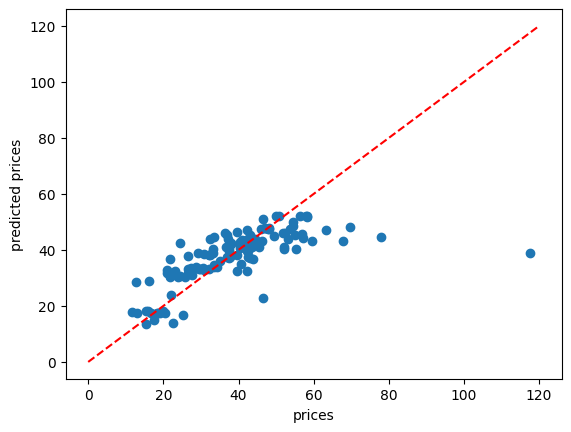

In [29]:
from sklearn.preprocessing import StandardScaler


model = LinearRegression()
model.fit(X_train, Y_train)

Y_pred = model.predict(X_test)

print("mae : ",mean_absolute_error(Y_test, Y_pred))
print("mse : ",sqrt(mean_squared_error(Y_test,Y_pred)))

plt.scatter(Y_test,Y_pred)
plt.plot()
plt.xlabel('prices')
plt.ylabel('predicted prices')
plt.plot([0, 120], [0, 120], color='red', linestyle='--', label='y=x')


lreg_coefficient = pd.DataFrame()
lreg_coefficient["Columns"] = X_train.columns
lreg_coefficient['Coefficient Estimate'] = pd.Series(model.coef_)
print(lreg_coefficient)


## Polynomial Regression

5.750057750832642
10.077798388974816


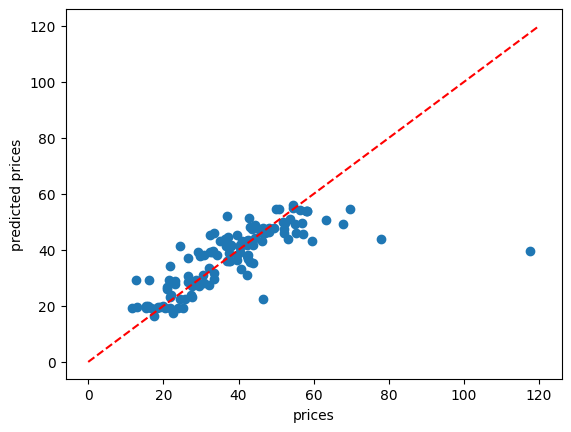

In [30]:
# Fitting Polynomial Regression to the dataset
from sklearn.preprocessing import PolynomialFeatures
 
# Polynomial feature transformation
degree = 2
poly = PolynomialFeatures(degree)
X_poly = poly.fit_transform(X_train)

# Fit polynomial regression model
model = LinearRegression()
model.fit(X_poly, Y_train)


X_test_poly = poly.transform(X_test)
Y_pred = model.predict(X_test_poly)

print(mean_absolute_error(Y_test, Y_pred))
print(sqrt(mean_squared_error(Y_test,Y_pred)))

plt.scatter(Y_test,Y_pred)
plt.plot()
plt.xlabel('prices')
plt.ylabel('predicted prices')
plt.plot([0, 120], [0, 120], color='red', linestyle='--', label='y=x')





## Ridge Regression

6.516114422250075
10.715555710780874
                                  Columns  Coefficient Estimate
0                            X2 house age             -0.210173
1  X3 distance to the nearest MRT station             -0.004943
2         X4 number of convenience stores              1.402034


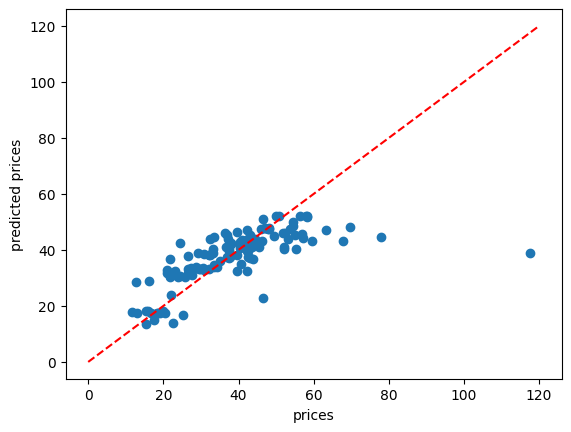

In [34]:
from sklearn.linear_model import Ridge

#Ridge Regression Model

ridgeReg = Ridge(alpha=1)
ridgeReg.fit(X_train,Y_train)
Y_pred = ridgeReg.predict(X_test)

print(mean_absolute_error(Y_test, Y_pred))
print(sqrt(mean_squared_error(Y_test,Y_pred)))

plt.scatter(Y_test,Y_pred)
plt.plot()
plt.xlabel('prices')
plt.ylabel('predicted prices')
plt.plot([0, 120], [0, 120], color='red', linestyle='--', label='y=x')

Rreg_coefficient = pd.DataFrame()
Rreg_coefficient["Columns"] = X_train.columns
Rreg_coefficient['Coefficient Estimate'] = pd.Series(ridgeReg.coef_)
print(Rreg_coefficient)



## Lasso Regression

7.000900098751572
11.049582968439326
                                  Columns  Coefficient Estimate
0                            X2 house age             -0.131627
1  X3 distance to the nearest MRT station             -0.006960
2         X4 number of convenience stores              0.000000


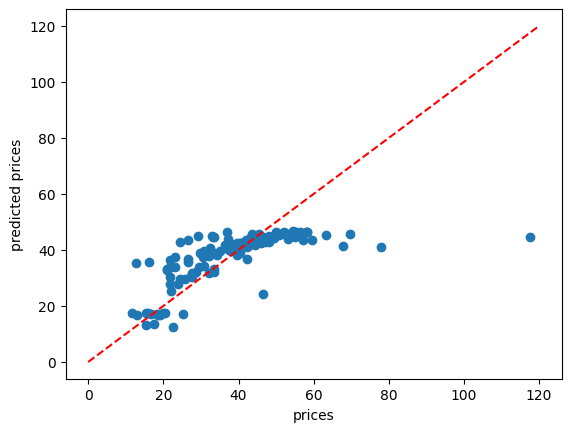

In [32]:
from sklearn.linear_model import Lasso
#lasso Regression Model
lassoReg = Lasso(alpha=10)

lassoReg.fit(X_train,Y_train)
Y_pred = lassoReg.predict(X_test)

print(mean_absolute_error(Y_test, Y_pred))
print(sqrt(mean_squared_error(Y_test,Y_pred)))

plt.scatter(Y_test,Y_pred)
plt.plot()
plt.xlabel('prices')
plt.ylabel('predicted prices')
plt.plot([0, 120], [0, 120], color='red', linestyle='--', label='y=x')

lreg_coefficient = pd.DataFrame()
lreg_coefficient["Columns"] = X_train.columns
lreg_coefficient['Coefficient Estimate'] = pd.Series(lassoReg.coef_)
print(lreg_coefficient)

## Elastic Net Regression

,Columns,Coefficient Estimate
0,X2 house age,-0.163685
1,X3 distance to the nearest MRT station,-0.006600
2,X4 number of convenience stores,0.246940


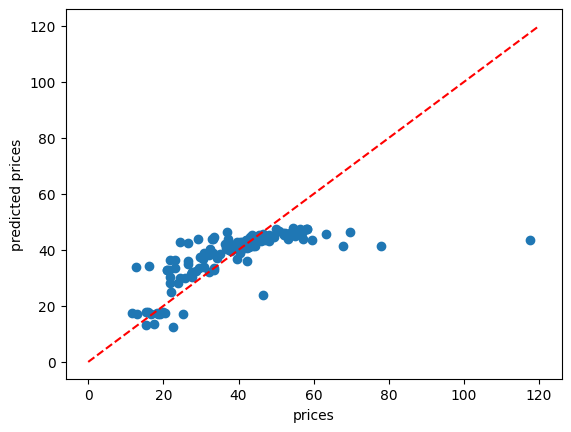

In [33]:
from sklearn.linear_model import ElasticNet

# Train the model
e_net = ElasticNet(alpha = 10)
e_net.fit(X_train, Y_train)
 
# calculate the prediction and mean square error
Y_pred = e_net.predict(X_test)


plt.scatter(Y_test,Y_pred)
plt.plot()
plt.xlabel('prices')
plt.ylabel('predicted prices')
plt.plot([0, 120], [0, 120], color='red', linestyle='--', label='y=x')
 
e_net_coeff = pd.DataFrame()
e_net_coeff["Columns"] = X_train.columns
e_net_coeff['Coefficient Estimate'] = pd.Series(e_net.coef_)
e_net_coeff

## XGBoost Regression 

In [36]:
import xgboost as xg
from sklearn.metrics import mean_squared_error as MSE 

# Train and test set are converted to DMatrix objects, 
# as it is required by learning API. 
train_dmatrix = xg.DMatrix(data = X_train, label = Y_train) 
test_dmatrix = xg.DMatrix(data = X_test, label = Y_test) 
  
# Parameter dictionary specifying base learner 
param = {"booster":"gblinear", "objective":"reg:linear"} 
  
xgb_r = xg.train(params = param, dtrain = train_dmatrix, num_boost_round = 10) 
pred = xgb_r.predict(test_dmatrix) 
  
# RMSE Computation 
rmse = np.sqrt(MSE(Y_test, pred)) 
print("RMSE : % f" %(rmse)) 

RMSE :  10.881867


C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\xgboost\core.py:160: UserWarning: [21:47:25] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-0b3782d1791676daf-1\xgboost\xgboost-ci-windows\src\objective\regression_obj.cu:209: reg:linear is now deprecated in favor of reg:squarederror.
  warnings.warn(smsg, UserWarning)


# Assosiation Rules

In [38]:
# 0. Import Libraries

import itertools
import pandas as pd
import numpy as np
from mlxtend.frequent_patterns import apriori, association_rules

# 1. Data Loading
df = pd.read_csv("C:\\Users\\Arian\\Desktop\\Dm_project2\\grocery.csv", names = ['products'], sep = ',')

# 2. Preprocess Data
df = df.drop_duplicates(ignore_index=True)
# print(df)
data = list(df["products"].apply(lambda x:x.split(",") ))
# print("\n",data)
# 3. Apply TransactionEncoder

from mlxtend.preprocessing import TransactionEncoder
encoder = TransactionEncoder()
a_data = encoder.fit(data).transform(data)
df = pd.DataFrame(a_data,columns=encoder.columns_)
df = df.replace(False,0)
# print("\n",df)
# 4. Generate Frequent Itemsets
df = apriori(df, min_support = 0.2, use_colnames = True, verbose = 1)
# print("\n",df)

# 5. Generate Association Rules
df_ar = association_rules(df, metric = "confidence", min_threshold = 0.6)
print("\n",df_ar)

# 6. Display Rules
for index in range(len(df_ar)):
    print(list(df_ar.loc[index].at["antecedents"]) ," ==> ", list(df_ar.loc[index].at["consequents"]))
   


Processing 12 combinations | Sampling itemset size 3

   antecedents consequents  antecedent support  consequent support   support  \
0   (BISCUIT)     (BREAD)            0.352941            0.647059  0.235294   
1      (MILK)     (BREAD)            0.294118            0.647059  0.235294   
2     (MAGGI)       (TEA)            0.294118            0.352941  0.235294   
3       (TEA)     (MAGGI)            0.352941            0.294118  0.235294   

   confidence      lift  leverage  conviction  zhangs_metric  
0    0.666667  1.030303  0.006920    1.058824       0.045455  
1    0.800000  1.236364  0.044983    1.764706       0.270833  
2    0.800000  2.266667  0.131488    3.235294       0.791667  
3    0.666667  2.266667  0.131488    2.117647       0.863636  
['BISCUIT']  ==>  ['BREAD']
['MILK']  ==>  ['BREAD']
['MAGGI']  ==>  ['TEA']
['TEA']  ==>  ['MAGGI']


C:\Users\Arian\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\mlxtend\frequent_patterns\fpcommon.py:110: DeprecationWarning: DataFrames with non-bool types result in worse computationalperformance and their support might be discontinued in the future.Please use a DataFrame with bool type
  warnings.warn(
